# فاز اول: شناخت داده‌ها و آمار توصیفی

## ۱. آماده‌سازی پروژه و بارگذاری داده‌ها

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

# مسیر اصلی پروژه
PROJECT_DIR = Path.cwd().parent

# مسیر فایل‌های خام
RAW_DIR = PROJECT_DIR / "data" / "raw"

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)

# نمایش فایل‌های موجود
for file in RAW_DIR.iterdir():
    print(file.name, "|", file.stat().st_size, "bytes")

Project directory: c:\Users\abaas\OneDrive\Desktop\آمار و کاربرد آن\NHANES_Project
Raw data directory: c:\Users\abaas\OneDrive\Desktop\آمار و کاربرد آن\NHANES_Project\data\raw
BMX_L.xpt | 1563200 bytes
BPXO_L.xpt | 696720 bytes
DEMO_L.xpt | 2582160 bytes


## ۲. بررسی اولیه داده‌ها

In [4]:
# خواندن فایل‌های NHANES
demo = pd.read_sas(RAW_DIR / "DEMO_L.xpt")
bmx = pd.read_sas(RAW_DIR / "BMX_L.xpt")
bpxo = pd.read_sas(RAW_DIR / "BPXO_L.xpt")

# نمایش ابعاد فایل‌ها
print("DEMO_L:", demo.shape)
print("BMX_L:", bmx.shape)
print("BPXO_L:", bpxo.shape)

DEMO_L: (11933, 27)
BMX_L: (8860, 22)
BPXO_L: (7801, 12)


In [5]:
print("DEMO_L variables:")
print(demo.columns.tolist())

print("\nBMX_L variables:")
print(bmx.columns.tolist())

print("\nBPXO_L variables:")
print(bpxo.columns.tolist())

DEMO_L variables:
['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR']

BMX_L variables:
['SEQN', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMDBMIC', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWAIST', 'BMXHIP', 'BMIHIP']

BPXO_L variables:
['SEQN', 'BPAOARM', 'BPAOCSZ', 'BPXOSY1', 'BPXODI1', 'BPXOSY2', 'BPXODI2', 'BPXOSY3', 'BPXODI3', 'BPXOPLS1', 'BPXOPLS2', 'BPXOPLS3']


## ۳. ارزیابی کیفیت داده‌ها

In [6]:
# بررسی شناسه‌های شرکت‌کنندگان در هر فایل

datasets = {
    "DEMO_L": demo,
    "BMX_L": bmx,
    "BPXO_L": bpxo
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 30)

    print("Total rows:", len(df))
    print("Unique SEQN:", df["SEQN"].nunique())
    print("Missing SEQN:", df["SEQN"].isna().sum())
    print("Duplicate SEQN:", df["SEQN"].duplicated().sum())


DEMO_L
------------------------------
Total rows: 11933
Unique SEQN: 11933
Missing SEQN: 0
Duplicate SEQN: 0

BMX_L
------------------------------
Total rows: 8860
Unique SEQN: 8860
Missing SEQN: 0
Duplicate SEQN: 0

BPXO_L
------------------------------
Total rows: 7801
Unique SEQN: 7801
Missing SEQN: 0
Duplicate SEQN: 0


In [7]:
# تعداد اندازه‌گیری‌های معتبر فشار سیستولیک برای هر فرد

bp_columns = ["BPXOSY1", "BPXOSY2", "BPXOSY3"]

bpxo["Valid_Systolic_Readings"] = bpxo[bp_columns].notna().sum(axis=1)

print(bpxo["Valid_Systolic_Readings"].value_counts().sort_index())

Valid_Systolic_Readings
0     283
1      12
2      28
3    7478
Name: count, dtype: int64


In [8]:
# متغیرهای اصلی موردنیاز پروژه
key_variables = {
    "DEMO_L": ["RIDAGEYR", "RIAGENDR", "WTMEC2YR"],
    "BMX_L": ["BMXBMI"],
    "BPXO_L": ["BPXOSY1", "BPXOSY2", "BPXOSY3"]
}

# بررسی مقادیر گمشده
for name, variables in key_variables.items():
    df = datasets[name]

    print(f"\n{name}")
    print("-" * 40)

    for var in variables:
        missing = df[var].isna().sum()
        percentage = missing / len(df) * 100

        print(
            f"{var}: {missing} missing "
            f"({percentage:.2f}%)"
        )


DEMO_L
----------------------------------------
RIDAGEYR: 0 missing (0.00%)
RIAGENDR: 0 missing (0.00%)
WTMEC2YR: 0 missing (0.00%)

BMX_L
----------------------------------------
BMXBMI: 389 missing (4.39%)

BPXO_L
----------------------------------------
BPXOSY1: 284 missing (3.64%)
BPXOSY2: 296 missing (3.79%)
BPXOSY3: 321 missing (4.11%)


## ۴. پاک‌سازی سن و انتخاب جمعیت بزرگسال

In [9]:
# بررسی وضعیت شرکت‌کنندگان
print("RIDSTATR - Examination Status:")
print(demo["RIDSTATR"].value_counts(dropna=False).sort_index())

# بررسی توزیع سن
print("\nAge Statistics:")
print(demo["RIDAGEYR"].describe())

# تعداد افراد زیر و بالای 20 سال
print("\nAge Groups:")
print("Under 20:", (demo["RIDAGEYR"] < 20).sum())
print("20 and older:", (demo["RIDAGEYR"] >= 20).sum())

RIDSTATR - Examination Status:
RIDSTATR
1.0    3073
2.0    8860
Name: count, dtype: int64

Age Statistics:
count    1.193300e+04
mean     3.831786e+01
std      2.560199e+01
min      5.397605e-79
25%      1.300000e+01
50%      3.700000e+01
75%      6.200000e+01
max      8.000000e+01
Name: RIDAGEYR, dtype: float64

Age Groups:
Under 20: 4124
20 and older: 7809


In [10]:
print("\nFirst 5 rows:")
display(demo.head())

print("\nSelected columns:")
display(demo[["SEQN", "RIDAGEYR", "RIDSTATR", "RIAGENDR"]].head(10))


First 5 rows:


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,2.0,5.00
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,2.0,5.00
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,1.0,1.41
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.268902,55698.607106,182.0,2.0,1.53
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.519774,36434.146346,182.0,2.0,3.60



Selected columns:


,SEQN,RIDAGEYR,RIDSTATR,RIAGENDR
0,130378.0,43.0,2.0,1.0
1,130379.0,66.0,2.0,1.0
2,130380.0,44.0,2.0,2.0
3,130381.0,5.0,2.0,2.0
4,130382.0,2.0,2.0,1.0
5,130383.0,3.0,1.0,2.0
6,130384.0,43.0,1.0,1.0
7,130385.0,65.0,1.0,2.0
8,130386.0,34.0,2.0,1.0
9,130387.0,68.0,2.0,2.0


In [11]:
# بررسی نوع داده و مقادیر گمشده سن
print("Data type:", demo["RIDAGEYR"].dtype)
print("Missing values:", demo["RIDAGEYR"].isna().sum())

# بررسی کوچک‌ترین و بزرگ‌ترین مقادیر
print("Minimum age:", demo["RIDAGEYR"].min())
print("Maximum age:", demo["RIDAGEYR"].max())

# نمایش فراوانی سن‌های کمتر از 1
print("\nValues below 1:")
print(demo.loc[demo["RIDAGEYR"] < 1, "RIDAGEYR"].value_counts())

Data type: float64
Missing values: 0
Minimum age: 5.397605346934028e-79
Maximum age: 80.0

Values below 1:
RIDAGEYR
5.397605e-79    189
Name: count, dtype: int64


In [12]:
# ایجاد نسخه‌ای از داده‌ها برای پاک‌سازی
demo_clean = demo.copy()

# شناسایی کد غیرعادی در متغیر سن
special_missing = demo_clean["RIDAGEYR"] < 1e-10

# تبدیل این مقادیر به NaN
demo_clean.loc[special_missing, "RIDAGEYR"] = np.nan

# بررسی نتیجه
print("Corrected values:", special_missing.sum())
print("Missing ages after correction:", demo_clean["RIDAGEYR"].isna().sum())
print("Minimum age after correction:", demo_clean["RIDAGEYR"].min())

Corrected values: 189
Missing ages after correction: 189
Minimum age after correction: 1.0


In [13]:
print("Total participants:", len(demo_clean))

print("Missing ages:", demo_clean["RIDAGEYR"].isna().sum())

print("Participants aged 20 or older:",
      (demo_clean["RIDAGEYR"] >= 20).sum())

print("Participants younger than 20:",
      (demo_clean["RIDAGEYR"] < 20).sum())

Total participants: 11933
Missing ages: 189
Participants aged 20 or older: 7809
Participants younger than 20: 3935


## ۵. بررسی شاخص توده بدنی (BMI)

In [14]:
# بررسی متغیر BMI در فایل BMX_L

print("Total participants:", len(bmx))
print("Missing BMI values:", bmx["BMXBMI"].isna().sum())

print("\nBMI Statistics:")
print(bmx["BMXBMI"].describe())

print("\nSmallest BMI values:")
print(bmx["BMXBMI"].nsmallest(10).to_list())

print("\nLargest BMI values:")
print(bmx["BMXBMI"].nlargest(10).to_list())

Total participants: 8860
Missing BMI values: 389

BMI Statistics:
count    8471.000000
mean       27.246665
std         8.137781
min        11.100000
25%        21.600000
50%        26.400000
75%        31.700000
max        74.800000
Name: BMXBMI, dtype: float64

Smallest BMI values:
[11.1, 12.4, 12.5, 12.5, 12.7, 12.9, 12.9, 12.9, 13.0, 13.1]

Largest BMI values:
[74.8, 69.9, 69.1, 68.9, 68.5, 67.8, 67.1, 66.6, 66.5, 66.1]


In [15]:
Q1 = bmx["BMXBMI"].quantile(0.25)
Q3 = bmx["BMXBMI"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = bmx[
    (bmx["BMXBMI"] < lower_bound) |
    (bmx["BMXBMI"] > upper_bound)
]

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))
print("Percentage:", len(outliers) / bmx["BMXBMI"].notna().sum() * 100)

IQR: 10.099999999999998
Lower bound: 6.450000000000005
Upper bound: 46.849999999999994
Potential outliers: 189
Percentage: 2.23114154173061


## ۶. بررسی فشار خون سیستولیک

In [16]:
# بررسی آماری سه اندازه‌گیری فشار خون سیستولیک

bp_columns = ["BPXOSY1", "BPXOSY2", "BPXOSY3"]

for col in bp_columns:
    print(f"\n{col}")
    print("-" * 40)

    print("Missing:", bpxo[col].isna().sum())
    print(bpxo[col].describe())

    print("Minimum:", bpxo[col].min())
    print("Maximum:", bpxo[col].max())


BPXOSY1
----------------------------------------
Missing: 284
count    7517.000000
mean      119.288546
std        18.561052
min        61.000000
25%       106.000000
50%       117.000000
75%       130.000000
max       232.000000
Name: BPXOSY1, dtype: float64
Minimum: 61.0
Maximum: 232.0

BPXOSY2
----------------------------------------
Missing: 296
count    7505.000000
mean      119.079680
std        18.571271
min        59.000000
25%       106.000000
50%       116.000000
75%       129.000000
max       233.000000
Name: BPXOSY2, dtype: float64
Minimum: 59.0
Maximum: 233.0

BPXOSY3
----------------------------------------
Missing: 321
count    7480.000000
mean      118.917647
std        18.495220
min        50.000000
25%       106.000000
50%       116.000000
75%       129.000000
max       232.000000
Name: BPXOSY3, dtype: float64
Minimum: 50.0
Maximum: 232.0


In [17]:
for col in bp_columns:
    Q1 = bpxo[col].quantile(0.25)
    Q3 = bpxo[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = bpxo[
        (bpxo[col] < lower_bound) |
        (bpxo[col] > upper_bound)
    ]

    valid_count = bpxo[col].notna().sum()

    print(f"\n{col}")
    print("-" * 40)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Potential outliers:", len(outliers))
    print("Percentage:", round(len(outliers) / valid_count * 100, 2), "%")


BPXOSY1
----------------------------------------
IQR: 24.0
Lower bound: 70.0
Upper bound: 166.0
Potential outliers: 143
Percentage: 1.9 %

BPXOSY2
----------------------------------------
IQR: 23.0
Lower bound: 71.5
Upper bound: 163.5
Potential outliers: 185
Percentage: 2.47 %

BPXOSY3
----------------------------------------
IQR: 23.0
Lower bound: 71.5
Upper bound: 163.5
Potential outliers: 178
Percentage: 2.38 %


In [18]:
# ایجاد نسخه پاک‌سازی‌شده از داده‌های فشار خون
bpxo_clean = bpxo.copy()

# محاسبه میانگین اندازه‌گیری‌های معتبر هر فرد
bpxo_clean["Mean_Systolic_BP"] = (
    bpxo_clean[bp_columns].mean(axis=1)
)

# شمارش تعداد اندازه‌گیری‌های معتبر هر فرد
bpxo_clean["Valid_Systolic_Readings"] = (
    bpxo_clean[bp_columns].notna().sum(axis=1)
)

# بررسی نتیجه
print("Mean Systolic BP statistics:")
print(bpxo_clean["Mean_Systolic_BP"].describe())

print("\nNumber of valid readings per participant:")
print(
    bpxo_clean["Valid_Systolic_Readings"]
    .value_counts()
    .sort_index()
)

print("\nMissing mean BP:",
      bpxo_clean["Mean_Systolic_BP"].isna().sum())

Mean Systolic BP statistics:
count    7518.000000
mean      119.094418
std        18.151729
min        70.000000
25%       106.333333
50%       116.333333
75%       129.000000
max       232.333333
Name: Mean_Systolic_BP, dtype: float64

Number of valid readings per participant:
Valid_Systolic_Readings
0     283
1      12
2      28
3    7478
Name: count, dtype: int64

Missing mean BP: 283


## ۷. ادغام مجموعه‌داده‌ها و بررسی تطبیق افراد

In [19]:
# ادغام فایل‌های دموگرافیک و BMI
merged = demo_clean.merge(
    bmx[["SEQN", "BMXBMI"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# افزودن میانگین فشار خون سیستولیک
merged = merged.merge(
    bpxo_clean[["SEQN", "Mean_Systolic_BP",
                "Valid_Systolic_Readings"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# بررسی نتیجه
print("Merged dataset shape:", merged.shape)
print("Unique participants:", merged["SEQN"].nunique())

print("\nMissing values:")
print(
    merged[
        ["RIDAGEYR", "BMXBMI", "Mean_Systolic_BP"]
    ].isna().sum()
)

Merged dataset shape: (11933, 30)
Unique participants: 11933

Missing values:
RIDAGEYR             189
BMXBMI              3462
Mean_Systolic_BP    4415
dtype: int64


In [20]:
# تفکیک افراد بر اساس وضعیت معاینه
examined = demo_clean[demo_clean["RIDSTATR"] == 2]

# تعداد افراد معاینه‌شده بر اساس سن
print("Examined participants:", len(examined))
print("Under 8:", (examined["RIDAGEYR"] < 8).sum())
print("Age 8 and older:", (examined["RIDAGEYR"] >= 8).sum())
print("Missing age:", examined["RIDAGEYR"].isna().sum())

# بررسی تطبیق شناسه‌ها با فایل فشار خون
print("\nBPXO matching:")
print("Matched with BPXO:",
      examined["SEQN"].isin(bpxo["SEQN"]).sum())

print("Not matched with BPXO:",
      (~examined["SEQN"].isin(bpxo["SEQN"])).sum())

# بررسی تطبیق شناسه‌ها با فایل BMI
print("\nBMX matching:")
print("Matched with BMX:",
      examined["SEQN"].isin(bmx["SEQN"]).sum())

print("Not matched with BMX:",
      (~examined["SEQN"].isin(bmx["SEQN"])).sum())

Examined participants: 8860
Under 8: 926
Age 8 and older: 7801
Missing age: 133

BPXO matching:
Matched with BPXO: 7801
Not matched with BPXO: 1059

BMX matching:
Matched with BMX: 8860
Not matched with BMX: 0


## ۸. انتخاب نمونه تحلیلی

In [21]:
# مرحله اول: انتخاب افراد 20 سال به بالا
adult_data = merged[
    merged["RIDAGEYR"] >= 20
].copy()

print("Adults aged 20 or older:", len(adult_data))

# مرحله دوم: بررسی وجود BMI
with_bmi = adult_data[
    adult_data["BMXBMI"].notna()
].copy()

print("Adults with valid BMI:", len(with_bmi))

# مرحله سوم: بررسی وجود فشار خون
with_bp = with_bmi[
    with_bmi["Mean_Systolic_BP"].notna()
].copy()

print("Adults with valid BMI and BP:", len(with_bp))

# تعداد افراد حذف‌شده در هر مرحله
print("\nExcluded participants:")
print("Missing BMI:", len(adult_data) - len(with_bmi))
print("Missing BP among those with BMI:",
      len(with_bmi) - len(with_bp))

Adults aged 20 or older: 7809
Adults with valid BMI: 5970
Adults with valid BMI and BP: 5805

Excluded participants:
Missing BMI: 1839
Missing BP among those with BMI: 165


## ۹. وزن‌های نمونه‌گیری و طراحی پیمایش

In [22]:
print("Weight variable:")
print(merged["WTMEC2YR"].describe())

print("\nMissing weights:")
print(merged["WTMEC2YR"].isna().sum())

print("\nSurvey design variables:")
print("SDMVSTRA missing:", merged["SDMVSTRA"].isna().sum())
print("SDMVPSU missing:", merged["SDMVPSU"].isna().sum())

Weight variable:
count    1.193300e+04
mean     2.740414e+04
std      2.796296e+04
min      5.397605e-79
25%      5.397605e-79
50%      2.171785e+04
75%      3.834115e+04
max      2.271083e+05
Name: WTMEC2YR, dtype: float64

Missing weights:
0

Survey design variables:
SDMVSTRA missing: 0
SDMVPSU missing: 0


In [23]:
tiny_value = 5.397605346934028e-79

print("Count of tiny values:", (merged["WTMEC2YR"] == tiny_value).sum())

print("\nRIDSTATR distribution:")
print(merged["RIDSTATR"].value_counts(dropna=False))

print("\nWeight status by examination status:")
print(
    merged.groupby("RIDSTATR")["WTMEC2YR"]
    .agg(["count", "min", "median", "max"])
)

Count of tiny values: 3073

RIDSTATR distribution:
RIDSTATR
2.0    8860
1.0    3073
Name: count, dtype: int64

Weight status by examination status:
          count           min        median           max
RIDSTATR                                                 
1.0        3073  5.397605e-79  5.397605e-79  5.397605e-79
2.0        8860  4.581595e+03  2.911510e+04  2.271083e+05


In [24]:
tiny_value = 5.397605346934028e-79

valid_weight = with_bp[
    (with_bp["WTMEC2YR"].notna()) &
    (with_bp["WTMEC2YR"] > 0) &
    (with_bp["WTMEC2YR"] != tiny_value)
]

print("Final analytical sample:", len(with_bp))
print("Participants with valid weights:", len(valid_weight))
print("Participants without valid weights:", len(with_bp) - len(valid_weight))

Final analytical sample: 5805
Participants with valid weights: 5805
Participants without valid weights: 0


## ۱۰. آمار توصیفی

In [25]:
print("Unweighted means:")
print(with_bp[["BMXBMI", "Mean_Systolic_BP"]].mean())

print("\nWeighted means:")
for variable in ["BMXBMI", "Mean_Systolic_BP"]:
    weighted_mean = np.average(
        with_bp[variable],
        weights=with_bp["WTMEC2YR"]
    )
    print(f"{variable}: {weighted_mean:.3f}")


Unweighted means:
BMXBMI               29.730164
Mean_Systolic_BP    122.869308
dtype: float64

Weighted means:
BMXBMI: 29.600
Mean_Systolic_BP: 121.117


In [26]:
descriptive_stats = with_bp[
    ["BMXBMI", "Mean_Systolic_BP"]
].describe().T

descriptive_stats["IQR"] = (
    descriptive_stats["75%"] - descriptive_stats["25%"]
)

descriptive_stats

,count,mean,std,min,25%,50%,75%,max,IQR
BMXBMI,5805.0,29.730164,7.149446,11.1,24.700000,28.400000,33.500000,68.9,8.8
Mean_Systolic_BP,5805.0,122.869308,17.989238,70.0,110.666667,120.333333,132.666667,215.0,22.0


## ۱۱. نمایش نموداری داده‌ها

In [27]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

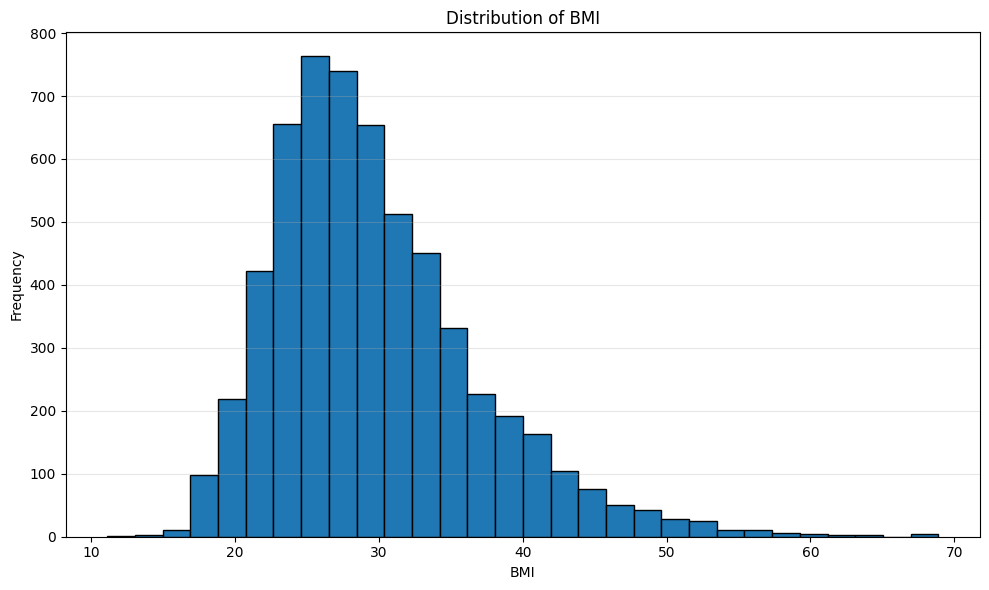

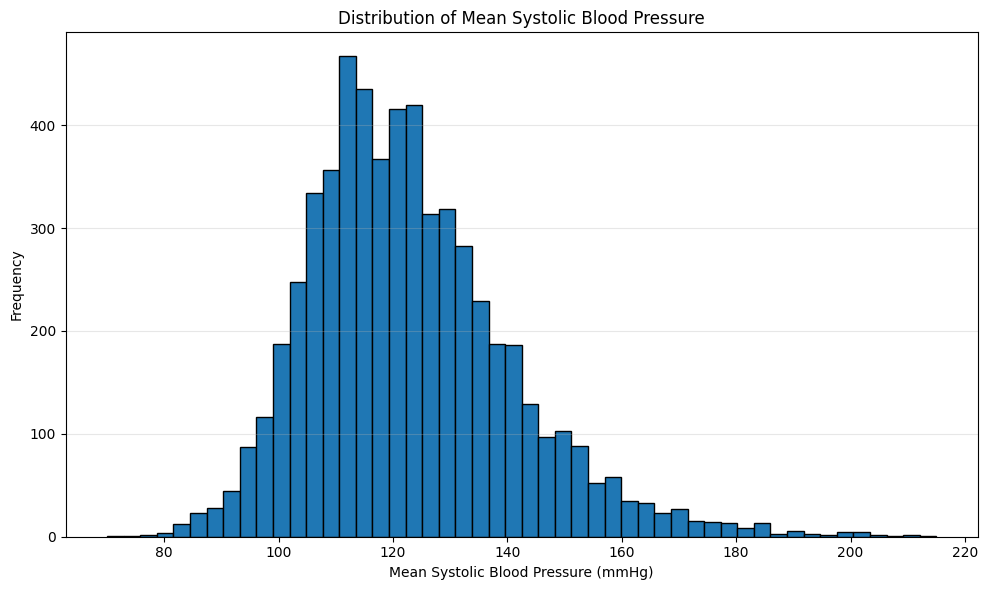

<Figure size 900x600 with 0 Axes>

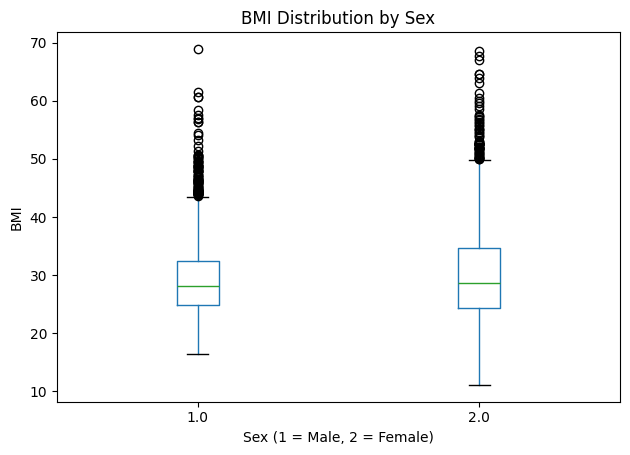

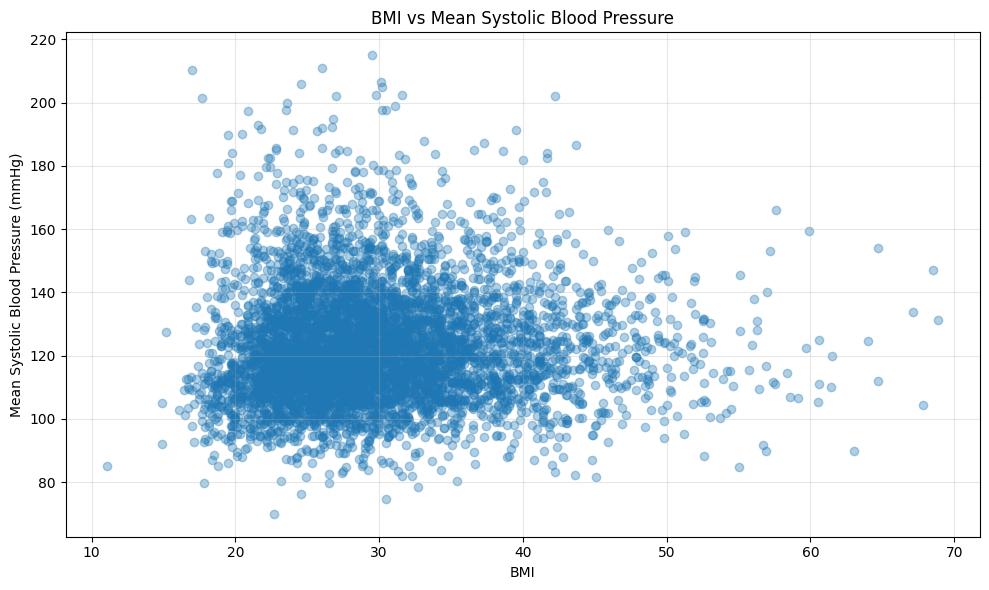

In [28]:
import matplotlib.pyplot as plt

# 1. BMI Histogram
plt.figure(figsize=(10, 6))

plt.hist(
    with_bp["BMXBMI"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "bmi_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. Systolic Blood Pressure Histogram
plt.figure(figsize=(10, 6))

plt.hist(
    with_bp["Mean_Systolic_BP"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Mean Systolic Blood Pressure")
plt.xlabel("Mean Systolic Blood Pressure (mmHg)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "systolic_bp_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. BMI Boxplot by Sex
plt.figure(figsize=(9, 6))

with_bp.boxplot(
    column="BMXBMI",
    by="RIAGENDR",
    grid=False
)

plt.title("BMI Distribution by Sex")
plt.suptitle("")
plt.xlabel("Sex (1 = Male, 2 = Female)")
plt.ylabel("BMI")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "bmi_by_sex_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 4. BMI vs Systolic Blood Pressure Scatterplot
plt.figure(figsize=(10, 6))

plt.scatter(
    with_bp["BMXBMI"],
    with_bp["Mean_Systolic_BP"],
    alpha=0.35
)

plt.title("BMI vs Mean Systolic Blood Pressure")
plt.xlabel("BMI")
plt.ylabel("Mean Systolic Blood Pressure (mmHg)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "bmi_vs_systolic_bp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
correlation = with_bp["BMXBMI"].corr(
    with_bp["Mean_Systolic_BP"]
)

print("Pearson Correlation:", correlation)

Pearson Correlation: 0.027355944339267795


## ۱۲. جداول فراوانی و مقایسه گروه‌ها

In [30]:
with_bp["Age_Group"] = pd.cut(
    with_bp["RIDAGEYR"],
    bins=[20, 40, 60, np.inf],
    labels=["20-39", "40-59", "60+"],
    right=False
)

with_bp["Sex"] = with_bp["RIAGENDR"].map({
    1: "Male",
    2: "Female"
})

print(with_bp[["RIDAGEYR", "Age_Group", "RIAGENDR", "Sex"]].head(10))

    RIDAGEYR Age_Group  RIAGENDR     Sex
0       43.0     40-59       1.0    Male
1       66.0       60+       1.0    Male
2       44.0     40-59       2.0  Female
8       34.0     20-39       1.0    Male
9       68.0       60+       2.0  Female
10      27.0     20-39       2.0  Female
11      59.0     40-59       1.0    Male
12      31.0     20-39       2.0  Female
13      33.0     20-39       2.0  Female
14      74.0       60+       2.0  Female


In [31]:
# Frequency table for sex
sex_frequency = with_bp["Sex"].value_counts()

sex_percentage = with_bp["Sex"].value_counts(normalize=True) * 100

sex_table = pd.DataFrame({
    "Frequency": sex_frequency,
    "Percentage": sex_percentage
})

print("Sex Frequency Table:")
display(sex_table.round(2))


# Frequency table for age groups
age_frequency = with_bp["Age_Group"].value_counts().sort_index()

age_percentage = with_bp["Age_Group"].value_counts(normalize=True).sort_index() * 100

age_table = pd.DataFrame({
    "Frequency": age_frequency,
    "Percentage": age_percentage
})

print("Age Group Frequency Table:")
display(age_table.round(2))

Sex Frequency Table:


,Frequency,Percentage
Sex,,
Female,3186,54.88
Male,2619,45.12


Age Group Frequency Table:


,Frequency,Percentage
Age_Group,,
20-39,1482,25.53
40-59,1668,28.73
60+,2655,45.74


In [32]:
age_comparison = with_bp.groupby("Age_Group", observed=True).agg(
    Count=("SEQN", "count"),
    Mean_BMI=("BMXBMI", "mean"),
    Median_BMI=("BMXBMI", "median"),
    Mean_Systolic_BP=("Mean_Systolic_BP", "mean"),
    Median_Systolic_BP=("Mean_Systolic_BP", "median")
)

display(age_comparison.round(2))

,Count,Mean_BMI,Median_BMI,Mean_Systolic_BP,Median_Systolic_BP
Age_Group,,,,,
20-39,1482,29.34,27.6,113.33,112.00
40-59,1668,30.48,29.0,121.43,119.67
60+,2655,29.48,28.5,129.10,127.00


In [33]:
sex_comparison = with_bp.groupby("Sex").agg(
    Count=("SEQN", "count"),
    Mean_BMI=("BMXBMI", "mean"),
    Median_BMI=("BMXBMI", "median"),
    Mean_Systolic_BP=("Mean_Systolic_BP", "mean"),
    Median_Systolic_BP=("Mean_Systolic_BP", "median")
)

display(sex_comparison.round(2))

,Count,Mean_BMI,Median_BMI,Mean_Systolic_BP,Median_Systolic_BP
Sex,,,,,
Female,3186,30.13,28.7,120.91,117.33
Male,2619,29.25,28.1,125.25,123.00


### ۱۲.۱ وزن‌های نمونه‌گیری و طراحی پیمایش

در پیمایش NHANES، به دلیل استفاده از روش نمونه‌گیری پیچیده، افراد شرکت‌کننده احتمال انتخاب یکسانی ندارند. بنابراین برای محاسبه برآوردهای مناسب از جامعه آماری، باید از وزن‌های نمونه‌گیری استفاده کرد.

در این پروژه، سه متغیر زیر برای بررسی وزن‌ها و ساختار نمونه‌گیری مورد استفاده قرار گرفته‌اند:

- `WTMEC2YR`: وزن نمونه‌گیری مربوط به معاینات انجام‌شده در مرکز معاینه سیار (MEC).
- `SDMVSTRA`: شناسه طبقه نمونه‌گیری.
- `SDMVPSU`: شناسه واحد نمونه‌گیری اولیه (PSU).

از آنجا که BMI و فشار خون سیستولیک هر دو از اطلاعات حاصل از معاینات پزشکی هستند، وزن معاینات یعنی `WTMEC2YR` برای محاسبه میانگین‌های وزن‌دار انتخاب شده است.

**نتایج بررسی وزن‌ها:**

در نمونه نهایی شامل ۵۸۰۵ شرکت‌کننده:
- هیچ مقدار گمشده‌ای در سه متغیر مذکور وجود نداشت.
- تمام وزن‌های نمونه‌گیری مثبت بودند.
- تعداد طبقات نمونه‌گیری ۱۵ و تعداد ترکیب‌های طبقه و واحد نمونه‌گیری اولیه ۳۰ بود.

**مقایسه میانگین‌های خام و وزن‌دار:**

میانگین‌های خام و وزن‌دار BMI و فشار خون سیستولیک با یکدیگر مقایسه شدند. نتایج نشان داد:

- میانگین خام BMI برابر ۲۹٫۷۳۰ و میانگین وزن‌دار آن برابر ۲۹٫۶۰۰ بود.
- میانگین خام فشار خون سیستولیک برابر ۱۲۲٫۸۶۹ و میانگین وزن‌دار آن برابر ۱۲۱٫۱۱۷ میلی‌متر جیوه بود.

این اختلاف‌ها نشان می‌دهند که استفاده از وزن‌های نمونه‌گیری بر برآورد میانگین متغیرها تأثیر می‌گذارد.

**نکته روش‌شناختی:**

میانگین‌های وزن‌دار فوق فقط با استفاده از وزن نمونه‌گیری محاسبه شده‌اند. برای انجام تحلیل‌های استنباطی و محاسبه صحیح خطاهای استاندارد، علاوه بر وزن‌ها باید ساختار طبقه‌بندی و خوشه‌بندی پیمایش نیز در نظر گرفته شود.

In [34]:
# Check survey weights and sampling design variables

design_columns = [
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU"
]

print("Missing values:")
print(with_bp[design_columns].isna().sum())

print("\nWeight summary:")
print(with_bp["WTMEC2YR"].describe().round(2))

print("\nNon-positive weights:")
print((with_bp["WTMEC2YR"] <= 0).sum())

print("\nNumber of unique strata:")
print(with_bp["SDMVSTRA"].nunique())

print("\nNumber of unique PSU codes:")
print(with_bp["SDMVPSU"].nunique())

print("\nNumber of unique stratum-PSU combinations:")
print(
    with_bp[["SDMVSTRA", "SDMVPSU"]]
    .drop_duplicates()
    .shape[0]
)

Missing values:
WTMEC2YR    0
SDMVSTRA    0
SDMVPSU     0
dtype: int64

Weight summary:
count      5805.00
mean      40525.85
std       29298.49
min        4581.60
25%       20253.59
50%       32040.00
75%       50415.78
max      227108.30
Name: WTMEC2YR, dtype: float64

Non-positive weights:
0

Number of unique strata:
15

Number of unique PSU codes:
2

Number of unique stratum-PSU combinations:
30


In [35]:
# Raw and weighted means

raw_bmi = with_bp["BMXBMI"].mean()
raw_bp = with_bp["Mean_Systolic_BP"].mean()

weighted_bmi = np.average(
    with_bp["BMXBMI"],
    weights=with_bp["WTMEC2YR"]
)

weighted_bp = np.average(
    with_bp["Mean_Systolic_BP"],
    weights=with_bp["WTMEC2YR"]
)

comparison = pd.DataFrame({
    "Variable": ["BMI", "Systolic Blood Pressure"],
    "Raw Mean": [raw_bmi, raw_bp],
    "Weighted Mean": [weighted_bmi, weighted_bp]
})

comparison["Difference"] = (
    comparison["Weighted Mean"] - comparison["Raw Mean"]
)

display(comparison.round(3))

,Variable,Raw Mean,Weighted Mean,Difference
0,BMI,29.730,29.600,-0.130
1,Systolic Blood Pressure,122.869,121.117,-1.753


### ۱۲.۲ نوع متغیرها و مقیاس‌های اندازه‌گیری

در این پژوهش، متغیرهای اصلی و کمکی از نظر نوع و مقیاس اندازه‌گیری به صورت زیر طبقه‌بندی می‌شوند:

**۱. شاخص توده بدنی (BMI)**
- نقش در پژوهش: متغیر اصلی
- نوع متغیر: کمی پیوسته
- مقیاس اندازه‌گیری: نسبتی

**۲. فشار خون سیستولیک**
- نقش در پژوهش: متغیر اصلی
- نوع متغیر: کمی پیوسته
- مقیاس اندازه‌گیری: نسبتی

**۳. سن**
- نقش در پژوهش: متغیر کمکی
- نوع متغیر: کمی گسسته (بر اساس سال کامل زندگی)
- مقیاس اندازه‌گیری: نسبتی

**۴. جنسیت**
- نقش در پژوهش: متغیر کمکی
- نوع متغیر: کیفی اسمی
- مقیاس اندازه‌گیری: اسمی

**۵. گروه سنی**
- نقش در پژوهش: متغیر مشتق‌شده
- نوع متغیر: کیفی رتبه‌ای
- مقیاس اندازه‌گیری: ترتیبی

### ۱۲.۳ انتخاب نمونه تحلیلی

برای انجام تحلیل‌های آماری، لازم بود شرکت‌کنندگانی انتخاب شوند که شرایط لازم برای ورود به پژوهش را داشته باشند.

فرایند انتخاب نمونه در سه مرحله انجام شد:

**مرحله اول: انتخاب افراد بزرگسال**

از مجموع ۱۱۹۳۳ شرکت‌کننده موجود در فایل `DEMO_L`، تعداد ۷۸۰۹ نفر دارای سن ۲۰ سال یا بیشتر بودند. افراد زیر ۲۰ سال از جامعه مورد مطالعه کنار گذاشته شدند.

**مرحله دوم: بررسی شاخص توده بدنی**

از میان ۷۸۰۹ فرد بزرگسال، تعداد ۵۹۷۰ نفر دارای مقدار معتبر برای متغیر `BMXBMI` بودند. افرادی که مقدار معتبر BMI نداشتند، از این مرحله به بعد وارد تحلیل نشدند.

**مرحله سوم: بررسی فشار خون سیستولیک**

از میان ۵۹۷۰ فرد باقی‌مانده، تعداد ۵۸۰۵ نفر دارای مقدار معتبر برای فشار خون سیستولیک بودند. برای محاسبه فشار خون هر فرد، میانگین اندازه‌گیری‌های معتبر موجود در متغیرهای `BPXOSY1`، `BPXOSY2` و `BPXOSY3` استفاده شد.

**نتیجه نهایی:**

در نهایت، نمونه تحلیلی پژوهش شامل ۵۸۰۵ شرکت‌کننده ۲۰ ساله و بالاتر است که برای هر دو متغیر BMI و فشار خون سیستولیک اطلاعات معتبر دارند.

این افراد مبنای محاسبات و تحلیل‌های بعدی پژوهش خواهند بود.

In [36]:
sample_selection = pd.DataFrame({
    "Stage": [
        "Total participants in DEMO_L",
        "Adults aged 20 or older",
        "Adults with valid BMI",
        "Adults with valid BMI and systolic BP"
    ],
    "Participants": [
        len(merged),
        len(adult_data),
        len(with_bmi),
        len(with_bp)
    ]
})

sample_selection["Excluded at this stage"] = [
    0,
    len(merged) - len(adult_data),
    len(adult_data) - len(with_bmi),
    len(with_bmi) - len(with_bp)
]

display(sample_selection)

,Stage,Participants,Excluded at this stage
0,Total participants in DEMO_L,11933,0
1,Adults aged 20 or older,7809,4124
2,Adults with valid BMI,5970,1839
3,Adults with valid BMI and systolic BP,5805,165


### ۱۲.۴ تطبیق شرکت‌کنندگان بین فایل‌های NHANES

برای ترکیب اطلاعات جمعیت‌شناختی، شاخص‌های بدنی و فشار خون، سه مجموعه‌داده `DEMO_L`، `BMX_L` و `BPXO_L` با استفاده از شناسه منحصربه‌فرد شرکت‌کنندگان (`SEQN`) به یکدیگر متصل شدند.

**نتایج بررسی تطبیق فایل‌ها:**

- فایل `DEMO_L` شامل ۱۱۹۳۳ شرکت‌کننده بود.
- فایل `BMX_L` شامل ۸۸۶۰ شرکت‌کننده بود که تمام آن‌ها در فایل `DEMO_L` نیز حضور داشتند.
- فایل `BPXO_L` شامل ۷۸۰۱ شرکت‌کننده بود که تمام آن‌ها در فایل `DEMO_L` نیز حضور داشتند.
- تعداد ۷۸۰۱ شرکت‌کننده در هر سه مجموعه‌داده مشترک بودند.

از آنجا که فایل `DEMO_L` به‌عنوان مجموعه‌داده اصلی در عملیات ادغام با روش اتصال چپ (Left Join) استفاده شد، تمام ۱۱۹۳۳ شرکت‌کننده آن در مجموعه‌داده نهایی ادغام‌شده حفظ شدند.

افرادی که در فایل‌های اندازه‌گیری بدن یا فشار خون حضور نداشتند، در مجموعه‌داده ادغام‌شده باقی ماندند، اما در صورت نداشتن اطلاعات معتبر موردنیاز، در مراحل بعدی انتخاب نمونه تحلیلی کنار گذاشته شدند.

In [37]:
demo_ids = set(demo_clean["SEQN"])
bmx_ids = set(bmx["SEQN"])
bpxo_ids = set(bpxo["SEQN"])

print("DEMO participants:", len(demo_ids))
print("BMX participants:", len(bmx_ids))
print("BPXO participants:", len(bpxo_ids))

print("\nDEMO participants matched with BMX:",
      len(demo_ids & bmx_ids))

print("DEMO participants matched with BPXO:",
      len(demo_ids & bpxo_ids))

print("DEMO participants not matched with BMX:",
      len(demo_ids - bmx_ids))

print("DEMO participants not matched with BPXO:",
      len(demo_ids - bpxo_ids))

print("\nParticipants present in all three files:",
      len(demo_ids & bmx_ids & bpxo_ids))

DEMO participants: 11933
BMX participants: 8860
BPXO participants: 7801

DEMO participants matched with BMX: 8860
DEMO participants matched with BPXO: 7801
DEMO participants not matched with BMX: 3073
DEMO participants not matched with BPXO: 4132

Participants present in all three files: 7801


### ۱۲.۵ وضعیت معاینه و دسترسی به اطلاعات فشار خون

در این بخش، وضعیت معاینه شرکت‌کنندگان و ارتباط آن با حضور آن‌ها در فایل فشار خون (`BPXO_L`) بررسی شد. هدف این بررسی، مشخص کردن علت تفاوت تعداد شرکت‌کنندگان در فایل جمعیت‌شناختی و فایل فشار خون بود.

**۱. بررسی وضعیت معاینه افراد غایب در فایل BPXO_L**

از مجموع ۴۱۳۲ نفری که در فایل `DEMO_L` حضور داشتند اما در `BPXO_L` یافت نشدند:

- ۳۰۷۳ نفر فقط مصاحبه شده بودند و معاینه پزشکی نداشتند.
- ۱۰۵۹ نفر معاینه شده بودند، اما در فایل فشار خون حضور نداشتند.

**۲. بررسی وضعیت سنی افراد معاینه‌شده‌ای که در BPXO_L حضور نداشتند**

بررسی دقیق‌تر ۱۰۵۹ فرد معاینه‌شده نشان داد:

- ۹۲۶ نفر کمتر از ۸ سال سن داشتند.
- ۱۳۳ نفر دارای اطلاعات نامشخص درباره سن بودند.
- هیچ فردی با سن معتبر ۸ سال یا بیشتر در این گروه وجود نداشت.

**۳. نتیجه بررسی**

طبق مستندات NHANES، اندازه‌گیری فشار خون در این چرخه برای افراد ۸ ساله و بالاتر در نظر گرفته شده است.

نتایج بررسی داده‌ها با این معیار سنی سازگار است؛ به‌طوری‌که تمام افراد معاینه‌شده‌ای که سن معتبر ۸ سال یا بیشتر داشتند، در فایل `BPXO_L` نیز حضور داشتند.

با این حال، درباره ۱۳۳ نفری که سن مشخصی نداشتند، نمی‌توان با قطعیت علت عدم حضور در فایل فشار خون را تعیین کرد.

In [38]:
# Identify participants who are not present in BPXO_L
not_in_bpxo = demo_clean[~demo_clean["SEQN"].isin(bpxo["SEQN"])].copy()

# Compare examination status
print("Examination status among participants not in BPXO_L:")
print(not_in_bpxo["RIDSTATR"].value_counts(dropna=False).sort_index())

print("\nExamination status in the entire DEMO_L dataset:")
print(demo_clean["RIDSTATR"].value_counts(dropna=False).sort_index())

# Examine age distribution among participants not in BPXO_L
print("\nAge statistics among participants not in BPXO_L:")
print(not_in_bpxo["RIDAGEYR"].describe())

print("\nAge groups among participants not in BPXO_L:")
print(pd.cut(
    not_in_bpxo["RIDAGEYR"],
    bins=[0, 8, 20,  np.inf],
    labels=["Under 8", "8-19", "20+"],
    right=False
).value_counts().sort_index())

Examination status among participants not in BPXO_L:
RIDSTATR
1.0    3073
2.0    1059
Name: count, dtype: int64

Examination status in the entire DEMO_L dataset:
RIDSTATR
1.0    3073
2.0    8860
Name: count, dtype: int64

Age statistics among participants not in BPXO_L:
count    3943.000000
mean       27.273142
std        26.192962
min         1.000000
25%         5.000000
50%        14.000000
75%        49.000000
max        80.000000
Name: RIDAGEYR, dtype: float64

Age groups among participants not in BPXO_L:
RIDAGEYR
Under 8    1457
8-19        741
20+        1745
Name: count, dtype: int64


In [39]:
age_exam_table = pd.crosstab(
    demo_clean["RIDSTATR"],
    pd.cut(
        demo_clean["RIDAGEYR"],
        bins=[0, 8, 20, np.inf],
        labels=["Under 8", "8-19", "20+"],
        right=False
    ),
    margins=True,
    dropna=False
)

display(age_exam_table)

RIDAGEYR,Under 8,8-19,20+,All
RIDSTATR,,,,
1.0,531,741,1745,3073
2.0,926,1737,6064,8860
All,1457,2478,7809,11933


In [40]:
examined_not_in_bpxo = not_in_bpxo[
    not_in_bpxo["RIDSTATR"] == 2
].copy()

print("Examined participants not in BPXO_L:", len(examined_not_in_bpxo))

print("\nAge distribution:")
print(examined_not_in_bpxo["RIDAGEYR"].value_counts(dropna=False).sort_index())

print("\nParticipants aged 8 or older:",
      (examined_not_in_bpxo["RIDAGEYR"] >= 8).sum())

print("Participants with missing age:",
      examined_not_in_bpxo["RIDAGEYR"].isna().sum())

Examined participants not in BPXO_L: 1059

Age distribution:
RIDAGEYR
1.0    116
2.0    118
3.0    114
4.0    144
5.0    167
6.0    121
7.0    146
NaN    133
Name: count, dtype: int64

Participants aged 8 or older: 0
Participants with missing age: 133


### ۱۲.۶ منبع داده و روش نمونه‌گیری

**منبع داده:**

داده‌های این پژوهش از پیمایش ملی سلامت و تغذیه آمریکا (NHANES) تهیه شده‌اند. این پیمایش توسط مرکز ملی آمار سلامت (NCHS)، زیرمجموعه مراکز کنترل و پیشگیری از بیماری‌های آمریکا (CDC)، اجرا می‌شود.

داده‌های مورد استفاده به چرخه آگوست ۲۰۲۱ تا آگوست ۲۰۲۳ تعلق دارند.

**جامعه هدف:**

جامعه هدف NHANES، جمعیت غیرنظامی و غیرنهادینه‌شده ایالات متحده آمریکا است.

**روش گردآوری داده‌ها:**

اطلاعات NHANES از طریق مصاحبه با خانوارها و انجام معاینات جسمانی در مراکز معاینه سیار (MEC) گردآوری می‌شوند.

در این پژوهش از سه مجموعه‌داده زیر استفاده شده است:

- `DEMO_L`: شامل اطلاعات جمعیت‌شناختی، از جمله سن، جنسیت و متغیرهای مربوط به طراحی نمونه‌گیری.
- `BMX_L`: شامل اندازه‌گیری‌های بدنی، از جمله شاخص توده بدنی (BMI).
- `BPXO_L`: شامل اندازه‌گیری‌های فشار خون با دستگاه اسیلومتریک، از جمله فشار خون سیستولیک.

**روش نمونه‌گیری:**

NHANES از روش نمونه‌گیری احتمالی چندمرحله‌ای و پیچیده استفاده می‌کند که شامل طبقه‌بندی و خوشه‌بندی است. در این روش، احتمال انتخاب افراد یکسان نیست و برای محاسبه برآوردهای مناسب از جامعه هدف باید وزن‌های نمونه‌گیری در نظر گرفته شوند.

**منابع رسمی:**

۱. [مستندات طراحی نمونه و راهنمای تحلیل NHANES، چرخه ۲۰۲۱ تا ۲۰۲۳](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewbrief.aspx?Cycle=2021-2023)

۲. [معرفی پیمایش NHANES ـ مرکز ملی آمار سلامت آمریکا](https://www.cdc.gov/nchs/hus/sources-definitions/nhanes.htm)

### 12.7 سؤال آماری نهایی پژوهش

**سؤال اصلی پژوهش:**

آیا بین شاخص توده بدنی (BMI) و فشار خون سیستولیک در افراد بزرگسال ۲۰ ساله و بالاتر در ایالات متحده آمریکا رابطه آماری وجود دارد؟

**سؤالات تکمیلی پژوهش:**

۱. آیا رابطه بین BMI و فشار خون سیستولیک در گروه‌های سنی مختلف تفاوت دارد؟

۲. آیا میانگین BMI و فشار خون سیستولیک بین زنان و مردان متفاوت است؟

۳. آیا سن در توضیح رابطه بین BMI و فشار خون سیستولیک نقش دارد؟

**جامعه مورد مطالعه:**

این پژوهش بر افراد ۲۰ ساله و بالاتر تمرکز دارد که اندازه‌گیری معتبر BMI و فشار خون سیستولیک برای آن‌ها موجود است.

نمونه نهایی مورد استفاده در تحلیل شامل ۵۸۰۵ شرکت‌کننده از چرخه NHANES در فاصله آگوست ۲۰۲۱ تا آگوست ۲۰۲۳ است.

**نوع و محدوده پژوهش:**

این پژوهش از نوع مشاهده‌ای و مقطعی است. هدف آن بررسی روابط آماری بین متغیرهاست و نتایج آن به‌تنهایی رابطه علت و معلولی را اثبات نمی‌کنند.